# Thesis Ch. 6 §6.2: do ROUGE-L and BERTScore notice a wrong-paper abstract?

A check of the **metrics**, not of the thesis model. For 200 of the 945 evaluation papers, an
off-the-shelf model (`gpt-5.6-luna`, no training) wrote three abstracts from an identical prompt;
only the listed publications differ:

- **real citations** — the titles and abstracts of all the paper's recorded references;
- **random citations** — the same number of papers drawn at random from the joint graph
  (usually another field);
- **same-category citations** — the same number of ogbn-arxiv papers drawn at random from the
  paper's own arXiv category (right field, wrong paper).

All abstracts are scored against the paper's original abstract. A metric that represents the
content should give the two control abstracts clearly lower scores, also the same-category one.

- Inputs: `experiments/2026-11-16_metric-check-random-citations/{real,random,same_category}/scored.csv`
  (built by `build_inputs.py`, `generate.py`, `score.py` in that folder; design in its `README.md`).
- Metrics: ROUGE-L F1 (stemming) and BERTScore F1 (`roberta-large`, no rescaling), as in
  `src/evaluation/evaluate_detailed.py`; TF-IDF identification among the 200 original abstracts
  (chance top-1 0.5%); the judge's content agreement (`gpt-5.4-mini`): the mean of subfield,
  problem and task, each 0–3.
- Paired comparison per paper: real − control, mean and SE = sd/√n. AUC: probability that a
  real-citation abstract scores higher than a control abstract drawn independently (0.5 = no
  separation, 1 = complete separation; ties count half).
- Output: `diagrams/figures/evaluation/metric_check.{pdf,png}`.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../../diagrams")
import thesis_style as ts
ts.apply()

E = "../../experiments/2026-11-16_metric-check-random-citations/"
CONDITIONS = {"real": "real citations", "same_category": "random citations (same category)",
              "random": "random citations (any field)"}
scored = {c: pd.read_csv(E + c + "/scored.csv").set_index("node_id") for c in CONDITIONS}
common = sorted(set.intersection(*(set(df.index) for df in scored.values())))
scored = {c: df.loc[common] for c, df in scored.items()}
print(f"{len(common)} papers with all three abstracts scored")

200 papers with all three abstracts scored


## Numbers for the thesis

In [2]:
METRICS = {"rougeL_f": "ROUGE-L F1", "bertscore_f1": "BERTScore F1",
           "content": "judge content agreement (0-3)", "tfidf_top1": "TF-IDF top-1 (of 200)"}

def auc(a, b):
    a, b = np.asarray(a)[:, None], np.asarray(b)[None, :]
    return (a > b).mean() + 0.5 * (a == b).mean()

real = scored["real"]
rows = []
for control in ("same_category", "random"):
    other = scored[control]
    for col, name in METRICS.items():
        a, b = pd.to_numeric(real[col], errors="coerce"), pd.to_numeric(other[col], errors="coerce")
        ok = a.notna() & b.notna()
        a, b = a[ok], b[ok]
        d = a - b
        rows.append({"control": control, "metric": name, "papers": len(d), "real": a.mean(),
                     "control mean": b.mean(), "difference": d.mean(),
                     "SE": d.std(ddof=1) / np.sqrt(len(d)),
                     "control as % of real": 100 * b.mean() / a.mean(),
                     "real > control (%)": 100 * (d > 0).mean(), "equal (%)": 100 * (d == 0).mean(),
                     "AUC": auc(a, b)})
table = pd.DataFrame(rows).set_index(["control", "metric"])
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 220):
    print(table.to_string())

print()
for c, df in scored.items():
    w = df["generated_abstract"].astype(str).str.split().str.len()
    parts = ", ".join(f"{k} {pd.to_numeric(df[k]).mean():.2f}" for k in ("subfield", "problem", "task"))
    print(f"{c}: judge {parts}; content score 0 for {100 * (df['content'] == 0).mean():.1f}% of papers; "
          f"generated words median {w.median():.0f}")
print(f"original abstracts: words median {real['original_abstract'].astype(str).str.split().str.len().median():.0f}")

                                             papers  real  control mean  difference    SE  control as % of real  real > control (%)  equal (%)   AUC
control       metric                                                                                                                                
same_category ROUGE-L F1                        200 0.153         0.112       0.041 0.002                73.302              94.500      1.000 0.932
              BERTScore F1                      200 0.841         0.822       0.019 0.001                97.769              97.000      0.000 0.920
              judge content agreement (0-3)     200 2.030         0.252       1.778 0.061                12.397              94.500      4.500 0.959
              TF-IDF top-1 (of 200)             200 0.760         0.025       0.735 0.031                 3.289              73.500     26.500 0.867
random        ROUGE-L F1                        200 0.153         0.112       0.041 0.002                7

## Constructed sentence pairs (thesis Tab. 6.3)

Short scientific statements written for illustration, not data from the experiment. Three pairs
share most of their words but state clearly different things; one pair states the same thing in
different words. Scored by `experiments/2026-11-16_metric-check-random-citations/example_pairs.py`
(same ROUGE-L and BERTScore settings as the experiment; text A as the reference), which writes
`example_pairs.csv`.

In [3]:
pairs = pd.read_csv(E + "example_pairs.csv")
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    print(pairs.round(3).to_string(index=False))

                         kind                                                                                                  text_a                                                                                                 text_b  rougeL_f  bertscore_f1
             reversed finding Adding residual connections improves the accuracy of deep graph neural networks on node classification. Adding residual connections reduces the accuracy of deep graph neural networks on node classification.     0.929         0.994
                swapped roles                     We use a large language model to generate training data for a graph neural network.                    We use a graph neural network to generate training data for a large language model.     0.600         0.974
        different application                                 We propose a transformer model for detecting tumours in medical images.                          We propose a transformer model for detecting fraud in fina

## Figure (not in the thesis for now; replaced by Tab. 6.3, author 2026-11-16): ROUGE-L and BERTScore with real vs same-category citations

The thesis shows only the real and the same-category condition (author, 2026-11-16); the random
condition stays in the numbers above. Two panels with the same 200 papers: (a) ROUGE-L F1,
(b) BERTScore F1. Number of papers per bin; real citations blue solid, same-category citations
orange dashed.

**Suggested caption:** ROUGE-L F1 (a) and BERTScore F1 (b) of abstracts generated for 200
evaluation papers from the paper's real citations and from the same number of papers drawn from
its own arXiv category, each compared with the paper's original abstract. Both abstracts were
written by the same untrained language model from an identical prompt; only the listed
publications differ.

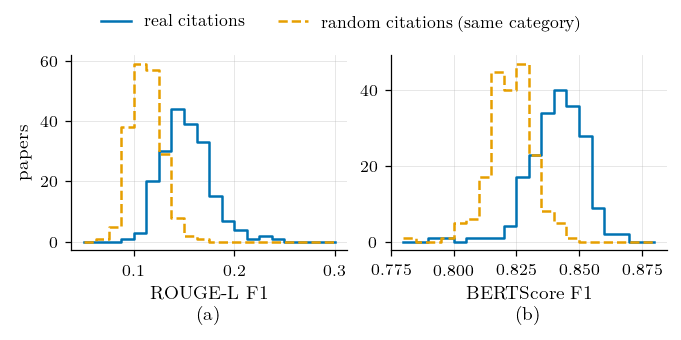

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(ts.FIGWIDTH, 55 * ts.MM), layout="constrained")
STYLE = {"real": dict(color=ts.COLORS["blue"], ls="-"),
         "same_category": dict(color=ts.COLORS["orange"], ls="--")}

def steps(ax, values, bins, **kw):
    counts, edges = np.histogram(values, bins=bins)
    ax.step(edges, np.append(counts, counts[-1]), where="post", **kw)

panels = [("rougeL_f", "ROUGE-L F1", np.linspace(0.05, 0.30, 21)),
          ("bertscore_f1", "BERTScore F1", np.linspace(0.78, 0.88, 21))]
for ax, (col, xlabel, bins), letter in zip(axes, panels, "ab"):
    for c in STYLE:
        steps(ax, pd.to_numeric(scored[c][col], errors="coerce").dropna(), bins,
              label=CONDITIONS[c], **STYLE[c])
    ax.set_xlabel(f"{xlabel}\n({letter})")  # panel letter under the axis label, inside the saved area
axes[0].set_ylabel("papers")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncol=2)
ts.save(fig, "metric_check", outdir="../../diagrams/figures/evaluation")
plt.show()